In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Разминочная задача

Как вы знаете, мы каждую неделю собираем с вас обратную связь по лекциям и семинарам в формате polls-опроса.

Мы получили $226$ пятерок, $42$ четвёрки, $22$ тройки, $8$ двоек и $5$ единиц.

Мы считаем, что наш CSAT является "выше всех ожиданий", если его среднее значение оказывается статистически значимо выше $4.5$. Мы считаем, что CSAT "в зелёной зоне", если среднее значение оказывается не меньше $4.5$.

Можем ли мы считать, что мы "выше всех ожиданий" или "в зелёной зоне"?

In [43]:
from scipy.stats import norm

In [44]:
x = np.repeat([5, 4, 3, 2, 1], [226, 42, 22, 8, 5])
n = 226 + 42 + 22 + 16 + 5

mean = x.mean()
se = x.std(ddof=1) / np.sqrt(len(x))
z = (mean - 4.5) / se

print("Всего наблюдений:", n)

print(f"Средняя оценка: {mean:.3f}")
print(f"Z-статистика: {z:.3f}")

print("Выше всех ожиданий:", z > norm.ppf(0.95))
print("В зелёной зоне:", mean >= 4.5)

Всего наблюдений: 311
Средняя оценка: 4.571
Z-статистика: 1.427
Выше всех ожиданий: False
В зелёной зоне: True


# Задача 1. Запуск нового тарифа

Продакт-менеджер предлагает изменить экран оплаты подписки.

Сейчас компания зарабатывает на нём в среднем **10 млн ₽ в месяц**.

Новый экран разработан с целью увеличить выручку. Если команда решит, что новый экран увеличивает выручку, его запустят для всех пользователей.

При этом полный запуск нового экрана стоит компании **1 млн ₽**: нужны доработки, дизайн, поддержка и маркетинг.

Если же новый экран действительно лучше, но компания его не запустит, она будет терять примерно **2 млн ₽ дополнительной выручки каждый месяц**.

**Задания**

1. Сформулируй $H_0$ и $H_1$.
2. Что здесь является ошибкой I рода?
3. Что является ошибкой II рода?
4. Какая из ошибок в данном примере потенциально дороже?
5. Что произойдёт в каждой ситуации:

   - новый экран не увеличивает выручку, но его запускают;
   - новый экран увеличивает выручку, но его не запускают.

**Решение**

**Основная гипотеза**

$$
H_0:\ \text{новый экран не увеличивает выручку}
$$

**Альтернативная гипотеза**

$$
H_1:\ \text{новый экран увеличивает выручку}
$$

**Ошибка I рода**

Команда решает, что новый экран увеличивает выручку, хотя на самом деле это не так.

Компания запускает бесполезное изменение и теряет **1 млн ₽** на запуск.

**Ошибка II рода**

Команда решает не запускать новый экран, хотя на самом деле он увеличивает выручку.

Компания недополучает примерно **2 млн ₽ каждый месяц**.

В этом примере ошибка II рода потенциально значительно дороже, особенно если упущенная прибыль сохраняется долго.

In [ ]:
type_1_cost = 1_000_000

type_2_cost_per_month = 2_000_000
months = 6

type_2_cost = type_2_cost_per_month * months

print('Ошибка I рода:', type_1_cost, '₽')
print('Ошибка II рода за 6 месяцев:', type_2_cost, '₽')

Ошибка I рода: 1000000 ₽
Ошибка II рода за 6 месяцев: 12000000 ₽


# Задача 2. Расчёт одновыборочного Z-критерия в python

In [ ]:
from scipy.stats import norm

Создадим функцию для расчёта квантильного значения нормального стандартного нормального распределения.

In [ ]:
np.random.seed(42)

def get_z_critical(alpha=0.05):
    return norm.ppf(1 - alpha/2)

Зададим параметры для демонстрации.

In [ ]:
population_mean = 100
population_std = 15
sample_size = 30

**Случай 1: очевидно разные средние**

Начнём с ручного расчёта.

In [ ]:
sample1 = np.random.normal(115, population_std, sample_size)
print(f"Выборка: среднее = {np.mean(sample1):.1f} vs популяция: среднее = {population_mean}")

sample_mean = np.mean(sample1)
n = len(sample1)
z_stat = (sample_mean - population_mean) / (population_std / np.sqrt(n))
z_critical = get_z_critical()

print(f"Z-статистика: {z_stat:.3f}")
print(f"Критическое значение: {z_critical:.3f}")

if abs(z_stat) > z_critical:
    print(f"Вывод: средние различаются (|{z_stat:.3f}| > {z_critical:.3f})")
else:
    print(f"Вывод: средние не различаются (|{z_stat:.3f}| ≤ {z_critical:.3f})")

Выборка: среднее = 112.2 vs популяция: среднее = 100
Z-статистика: 4.447
Критическое значение: 1.960
Вывод: средние различаются (|4.447| > 1.960)


Перейдём к автоматическому расчёту.

In [ ]:
from statsmodels.stats.weightstats import ztest

z_stat_auto, p_value = ztest(sample1, value=population_mean)
print(f"Z-статистика: {z_stat_auto:.3f}")

if abs(z_stat_auto) > z_critical:
    print(f"Вывод: средние различаются")
else:
    print(f"Вывод: средние не различаются")

Z-статистика: 4.941
Вывод: средние различаются


**Случай 2: очевидно одинаковые средние**

Проведём автоматический расчёт.

In [ ]:
sample2 = np.random.normal(101, population_std, sample_size)
print(f"Выборка: среднее = {np.mean(sample2):.1f} vs популяция: среднее = {population_mean}")

z_stat_auto, p_value = ztest(sample2, value=population_mean)
z_critical = get_z_critical()

print(f"Z-статистика: {z_stat_auto:.3f}")
print(f"Критическое значение: {z_critical:.3f}")

if abs(z_stat_auto) > z_critical:
    print(f"Вывод: средние различаются")
else:
    print(f"Вывод: средние не различаются")

Выборка: среднее = 99.2 vs популяция: среднее = 100
Z-статистика: -0.321
Критическое значение: 1.960
Вывод: средние не различаются


# Задача 3. Брак партии деталей

Вы работаете на заводе, на котором производятся детали для определённой продукции.

При производстве деталей заложен норматив для эталонного веса выпускаемой детали. Однако на заводе допускается некий разброс значений веса, так как абсолютного совпадения нормативам добиться невозможно.

Каждая партия проверяется на то, что средний вес деталей в ней *статистически значимо* не отличается от нормативного веса, который составляет для этого типа деталей $37.8$ кг.

**Задача:**

 1. Импортируй файл *detail_list_factory.csv* и визуализируй данные с помощью гистограммы и боксплота;

 2. Рассчитай вручную значение статистического Z-критерия;

 3. Проверь, что выборка деталей удовлетворяет нормативам  с помощью **двустороннего** Z-критерия;

 4. Проверь, что выборка деталей удовлетворяет нормативам с помощью **левостороннего** Z-критерия;

 5. Проверь, что выборка деталей удовлетворяет нормативам с помощью **правостороннего** Z-критерия;

Для всех тестов в качестве уровня значимости возьми $\alpha = 5\%$.

**Решение**

In [ ]:
df = pd.read_csv('detail_list_factory.csv')
df['weight_kg'] = df['detail_weight'] / 1000

df.head()

,detail_weight,weight_kg
0,37873,37.873
1,37808,37.808
2,37773,37.773
3,37824,37.824
4,37834,37.834


In [ ]:
due_weight = 37.8

avg_weight_kg = df['weight_kg'].mean()
n_det = len(df)

print(avg_weight_kg)
print(n_det)

37.80223547880691
637


## Пункт 1. Визуализация данных

**Построим гистограмму**

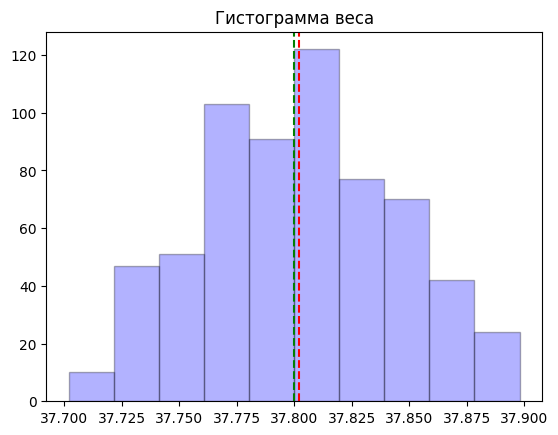

In [ ]:
plt.hist(df['weight_kg'], color='blue', alpha=0.3, edgecolor='black')
plt.axvline(due_weight, color='g', linestyle='--')
plt.axvline(avg_weight_kg, color='red', linestyle='--')
plt.title("Гистограмма веса")
plt.show()

**Построим боксплот**

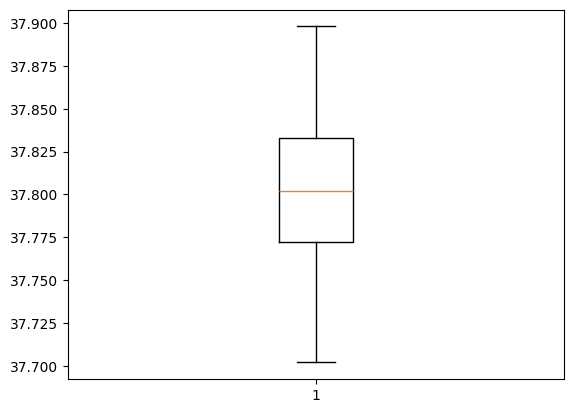

In [ ]:
plt.boxplot(df['weight_kg'])
plt.show()

## Пункт 2. Расчёт значения Z-критерия

**Теперь рассчитаем дисперсию и стандартное отклонение выборки**

In [ ]:
var_kg = df['weight_kg'].var()
std_kg = df['weight_kg'].std()

print(var_kg)
print(std_kg)

0.0017551394310990043
0.0418943842429866


**Рассчитаем одновыборочный z-критерий**

In [ ]:
z_calc = (avg_weight_kg - due_weight) / (var_kg / n_det)**.5

print(z_calc)

1.3467421771241477


**Необходимо сравнить его с квантильными значениями нормального стандартного распределения**

In [ ]:
from scipy.stats import norm

In [ ]:
alpha = 0.05

z_crit_1 = norm.ppf(alpha/2)
z_crit_2 = norm.ppf(1 - alpha/2)

print(z_crit_1)
print(z_crit_2)

-1.9599639845400545
1.959963984540054


In [ ]:
print(norm.cdf(z_crit_1))
print(norm.cdf(z_crit_2))

0.024999999999999977
0.975


## Пункт 3. Вывод по двустороннему Z-критерию

$H_0: \mu = \mu_0$

$H_1: \mu \neq \mu_0$

In [ ]:
p_val = 2*(1 - norm.cdf(z_calc))

print(p_val)

0.1780632833271305


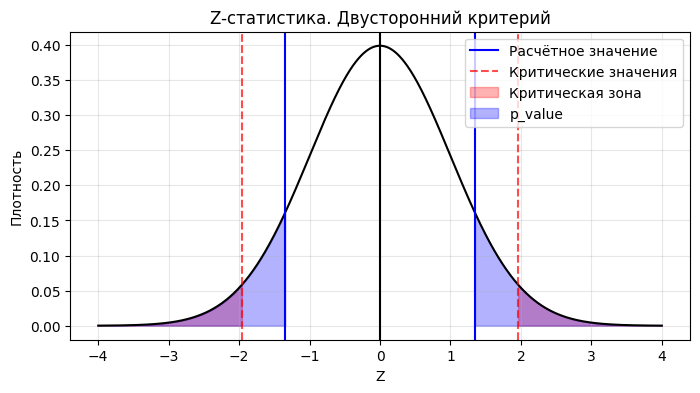

In [ ]:
x = np.linspace(-4, 4, 1000)
y = norm.pdf(x)

plt.figure(figsize=(8, 4))
plt.plot(x, y, 'black')
plt.axvline(z_calc, color='blue', label = 'Расчётное значение')
plt.axvline(-z_calc, color='blue')
plt.axvline(0, color='black')
plt.axvline(z_crit_1, color='red', linestyle='--', alpha=0.7, label='Критические значения')
plt.axvline(z_crit_2, color='red', linestyle='--', alpha=0.7)

# Закрашиваем критические области
x_fill_left = np.linspace(-4, z_crit_1, 100)
x_fill_right = np.linspace(z_crit_2, 4, 100)
plt.fill_between(x_fill_left, norm.pdf(x_fill_left), alpha=0.3, color='red', label = 'Критическая зона')
plt.fill_between(x_fill_right, norm.pdf(x_fill_right), alpha=0.3, color='red')

# Закрашиваем p_value
x_fill_pval_1 = np.linspace(z_calc, 4, 100)
x_fill_pval_2 = np.linspace(-4, -z_calc, 100)

plt.fill_between(x_fill_pval_1, norm.pdf(x_fill_pval_1), alpha=0.3, color='blue', label = 'p_value')
plt.fill_between(x_fill_pval_2, norm.pdf(x_fill_pval_2), alpha=0.3, color='blue')

plt.title("Z-статистика. Двусторонний критерий")
plt.xlabel('Z')
plt.ylabel('Плотность')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Вывод:**

Так как p_value больше уровня значимости, не можем отвергнуть гипотезу $H_0$.


## Пункт 4. Вывод по левостороннему Z-критерию

$H_0: \mu = \mu_0$

$H_1: \mu < \mu_0$

Рассчитаем критическое значение

In [ ]:
z_crit_left = norm.ppf(alpha)
print(z_crit_left)

-1.6448536269514729


Рассчитаем p_value

In [ ]:
p_val_left = norm.cdf(z_calc)
print(p_val_left)

0.9109683583364347


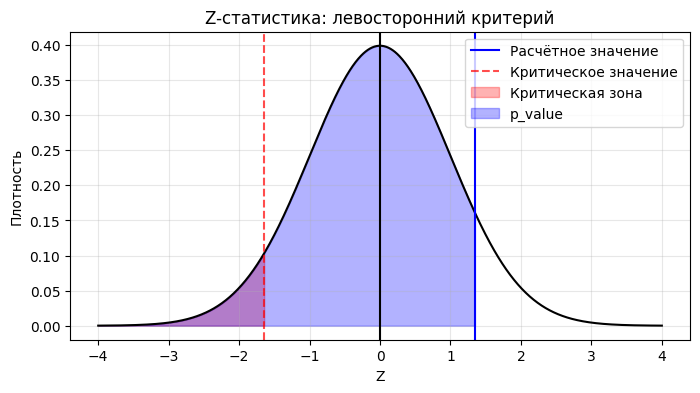

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(x, y, 'black')

plt.axvline(z_calc, color='blue', label='Расчётное значение')
plt.axvline(0, color='black')
plt.axvline(z_crit_left, color='red', linestyle='--', alpha=0.7, label='Критическое значение')

# Закрашиваем критическую область
x_fill_crit = np.linspace(-4, z_crit_left, 100)
plt.fill_between(x_fill_crit, norm.pdf(x_fill_crit),alpha=0.3,color='red',label='Критическая зона')

# Закрашиваем p_value
x_fill_pval = np.linspace(-4, z_calc, 100)
plt.fill_between(x_fill_pval,norm.pdf(x_fill_pval),alpha=0.3,color='blue',label='p_value')

plt.title("Z-статистика: левосторонний критерий")
plt.xlabel('Z')
plt.ylabel('Плотность')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Вывод:**

Так как p_value больше уровня значимости, не можем отвергнуть гипотезу $H_0$.

## Пункт 5. Вывод по правостороннему Z-критерию

$H_0: \mu = \mu_0$

$H_1: \mu > \mu_0$

In [ ]:
z_crit_right = norm.ppf(1 - alpha)
print(z_crit_right)

1.6448536269514722


In [ ]:
p_val_right = 1 - norm.cdf(z_calc)
print(p_val_right)

0.08903164166356525


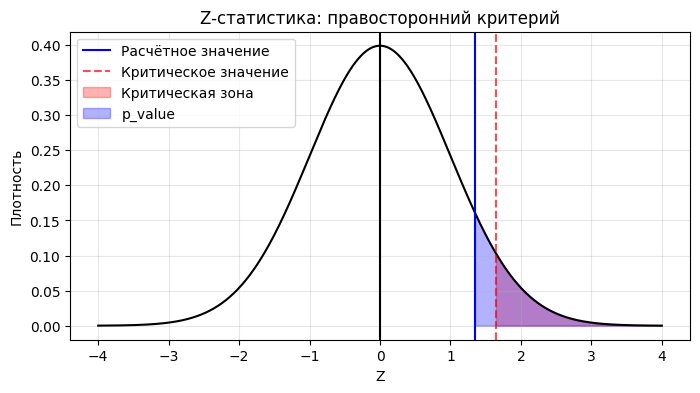

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(x, y, 'black')

plt.axvline(z_calc, color='blue', label='Расчётное значение')
plt.axvline(0, color='black')
plt.axvline(z_crit_right, color='red', linestyle='--', alpha=0.7, label='Критическое значение')

# Закрашиваем критическую область
x_fill_crit = np.linspace(z_crit_right, 4, 100)
plt.fill_between(x_fill_crit,norm.pdf(x_fill_crit),alpha=0.3,color='red',label='Критическая зона')

# Закрашиваем p_value
x_fill_pval = np.linspace(z_calc, 4, 100)
plt.fill_between(x_fill_pval,norm.pdf(x_fill_pval),alpha=0.3,color='blue',label='p_value')

plt.title("Z-статистика: правосторонний критерий")
plt.xlabel('Z')
plt.ylabel('Плотность')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Вывод:**

Так как p_value больше уровня значимости, не можем отвергнуть гипотезу $H_0$.

**Вывод:**

Так как p_value больше уровня значимости, не можем отвергнуть гипотезу $H_0$.


# Задача 4. Как аналитики нашли несуществующее улучшение

Команда маркетинга запустила новую рекламную кампанию.

Для оценки её эффективности аналитики решили проверить, изменились ли показатели в разных городах. Для каждого города проводится отдельный Z-тест.

Из исторических данных известно, что среднее значение показателя равно $\mu_0=100$, а стандартное отклонение составляет $\sigma=20$.

Для каждого города сформирована независимая выборка из $100$ наблюдений.

Проверяются гипотезы:

$$
H_0:\mu=100,\qquad H_1:\mu\neq100.
$$

Уровень значимости каждого теста $\alpha=0.05$.

**Важное обстоятельство:** на самом деле рекламная кампания не повлияла ни на один город. Во всех городах истинное среднее по-прежнему равно $100$.

Однако маркетологи об этом не знают и действуют по правилу:

**Если хотя бы в одном городе обнаружено статистически значимое изменение, кампания объявляется успешной.**



## Пункт 1. Один эксперимент

Смоделируй показатели для $10$ городов.

1. Сгенерируй для каждого города $100$ наблюдений из нормального распределения с параметрами $\mu=100$ и $\sigma=20$.
2. Рассчитай выборочное среднее для каждого города.
3. Для каждого города вычисли Z-статистику:

$$
Z=\frac{\overline X-\mu_0}{\sigma/\sqrt{100}}.
$$

4. Определи критическую область двустороннего Z-критерия при $\alpha=0.05$.
5. Выведи города, в которых удалось отвергнуть $H_0$.

**Вопросы:**

- Если хотя бы в одном городе отвергнута $H_0$, какую ошибку совершают маркетологи?
- Могут ли все $10$ тестов не обнаружить статистически значимых различий?
- Почему результаты тестирования разных городов отличаются, хотя истинные параметры распределений одинаковы?


In [ ]:
rng = np.random.default_rng(42)

mu0 = 100
sigma = 20
n = 100
cities = 10
alpha = 0.05

data = rng.normal(mu0, sigma, size=(10, n))
z = (data.mean(axis=1) - mu0) / (sigma / np.sqrt(n))
critical = norm.ppf(1 - alpha / 2)

print("Z-статистики:", np.round(z, 2))
print("Города с отклонённой H0:", np.where(abs(z) > critical)[0] + 1)


Z-статистики: [-0.5  -0.11 -0.62  1.02 -0.45 -0.91 -1.12  0.38 -1.64  1.06]
Города с отклонённой H0: []



## Часть 2. Тысяча рекламных кампаний

Теперь представим, что компания повторяет аналогичный эксперимент $1000$ раз.

В каждом эксперименте:

- исследуются $10$ независимых городов;
- во всех городах истинное среднее равно $100$;
- в каждом городе проводится двусторонний Z-тест;
- компания объявляет кампанию успешной, если хотя бы в одном городе отвергнута $H_0$.

**Задания:**

1. Смоделируй $1000$ таких экспериментов.
2. Посчитай, в какой доле экспериментов хотя бы один город показал статистически значимое изменение.
3. Построй гистограмму количества городов, в которых отвергнута $H_0$, для каждого эксперимента.
4. Повтори моделирование для $1$, $5$, $10$, $20$ и $50$ городов.
5. Построй график зависимости доли «успешных» кампаний от количества проверяемых городов.

**Вопрос:** почему вероятность объявить кампанию успешной может оказаться намного выше $5\%$, хотя для каждого отдельного теста $\alpha=0.05$?


**Решение**

In [ ]:
experiments = 1000
cities_list = [1, 5, 10, 20, 50]
old_results = []
new_results = []

for m in cities_list:
    data = rng.normal(mu0, sigma, size=(experiments, m, n))
    z = (data.mean(axis=2) - mu0) / (sigma / np.sqrt(n))

    old_critical = norm.ppf(1 - alpha / 2)
    new_critical = norm.ppf(1 - alpha / (2 * m))

    old_reject = np.abs(z) > old_critical
    new_reject = np.abs(z) > new_critical

    old_results.append(old_reject.any(axis=1).mean())
    new_results.append(new_reject.any(axis=1).mean())

    if m == 10:
        counts = old_reject.sum(axis=1)

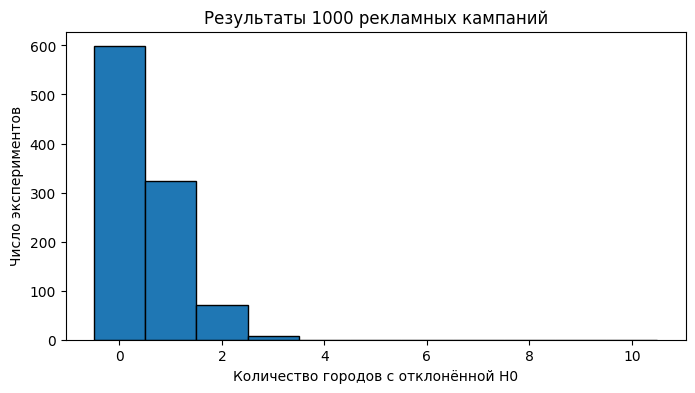

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(counts, bins=np.arange(-0.5, 11.5, 1), edgecolor='black')
plt.xlabel('Количество городов с отклонённой H0')
plt.ylabel('Число экспериментов')
plt.title('Результаты 1000 рекламных кампаний')
plt.show()

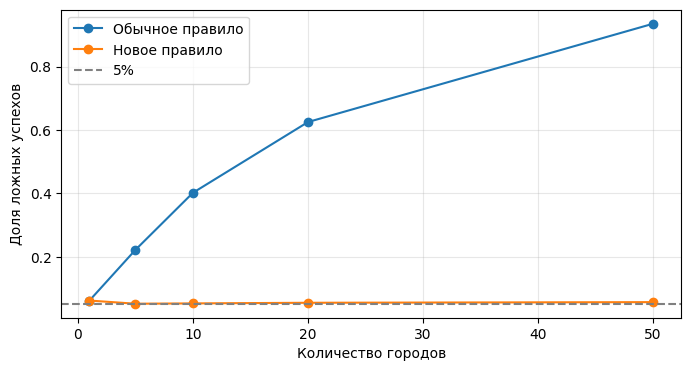

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(cities_list, old_results, 'o-', label='Обычное правило')
plt.plot(cities_list, new_results, 'o-', label='Новое правило')
plt.axhline(alpha, linestyle='--', color='gray', label='5%')
plt.xlabel('Количество городов')
plt.ylabel('Доля ложных успехов')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


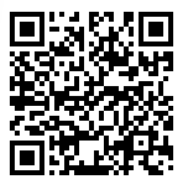